# Model Training 1: Linear Regression

In [1]:
# read data
import pandas as pd
train_df = pd.read_csv("../Data/TrainPreprocessed.csv")
test_df = pd.read_csv("../Data/TestPreprocessed.csv")

In [2]:
# separate features and label
X_train = train_df.drop(columns=["LIFETIME"])
y_train = train_df["LIFETIME"]

X_test = test_df.drop(columns=["LIFETIME"])
y_test = test_df["LIFETIME"]

### 1. Baseline Linear Regression

In [3]:
# imports
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [4]:
# train linear regressor
lr_model1 = LinearRegression()
lr_model1.fit(X_train, y_train)

LinearRegression()

In [5]:
# predict
y_pred_lr1 = lr_model1.predict(X_test)

In [6]:
# evaluate
mae_lr1 = mean_absolute_error(y_test, y_pred_lr1)
mse_lr1 = mean_squared_error(y_test, y_pred_lr1)
rmse_lr1 = np.sqrt(mse_lr1)
r2_lr1 = r2_score(y_test, y_pred_lr1)

print(f"Linear Regression Results:")
print(f"MAE: {mae_lr1:.2f}")
print(f"MSE: {mse_lr1:.2f}")
print(f"RMSE: {rmse_lr1:.2f}")
print(f"R² Score: {r2_lr1:.2f}")

Linear Regression Results:
MAE: 2559.95
MSE: 12378670.56
RMSE: 3518.33
R² Score: 0.44


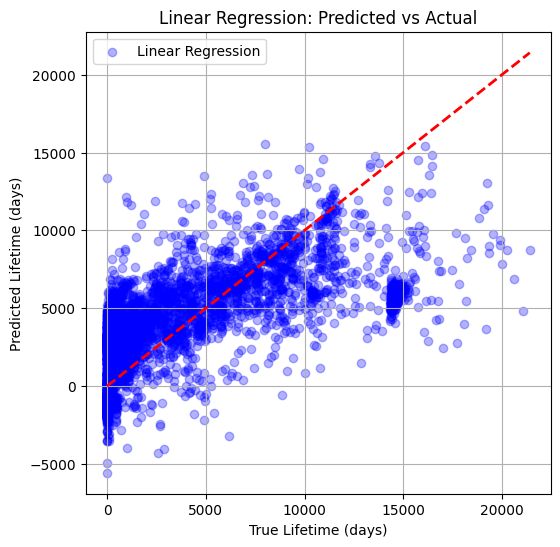

In [7]:
# visualize evaluation
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lr1, alpha=0.3, label="Linear Regression", color="blue")
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("Linear Regression: Predicted vs Actual")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.legend()
plt.grid(True)
plt.show()

### 2. Log-Transformed Label 
#### Target variable is skewed with long right tail. Log transforming compresses large values and expands small ones, turning skewed data into something more normal-like, maybe improving predictions.

In [8]:
# log transform label
y_train_log = np.log1p(y_train)  # log(1 + x), safe for zero
y_test_log = np.log1p(y_test)

In [9]:
# train model
lr_model2 = LinearRegression()
lr_model2.fit(X_train, y_train_log)

LinearRegression()

In [10]:
# predict and invert the log
y_pred_lr2_log = lr_model2.predict(X_test)
y_pred_lr2 = np.expm1(y_pred_lr2_log)  # exp(x) - 1, inverse of log1p


In [11]:
# evaluate 
mae_lr2 = mean_absolute_error(y_test, y_pred_lr2)
mse_lr2 = mean_squared_error(y_test, y_pred_lr2)
rmse_lr2 = np.sqrt(mse_lr2)
r2_lr2 = r2_score(y_test, y_pred_lr2)

print("Log-Transformed Linear Regression Results:")
print(f"MAE: {mae_lr2:.2f}")
print(f"MSE: {mse_lr2:.2f}")
print(f"RMSE: {rmse_lr2:.2f}")
print(f"R² Score: {r2_lr2:.2f}")

Log-Transformed Linear Regression Results:
MAE: 7318.94
MSE: 15248650898.40
RMSE: 123485.43
R² Score: -690.53


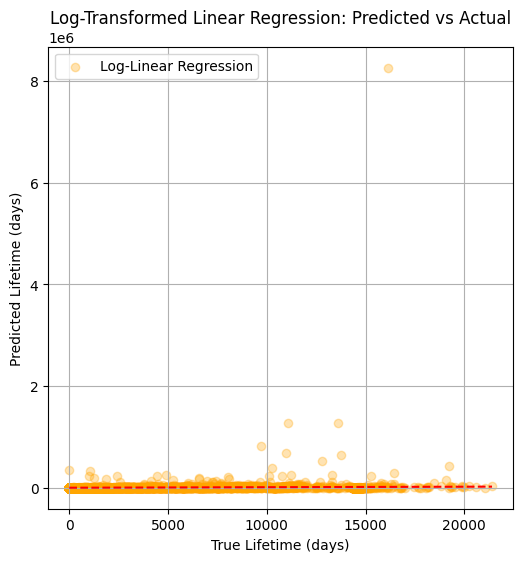

In [12]:
# visualize
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_lr2, alpha=0.3, color="orange", label="Log-Linear Regression")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("True Lifetime (days)")
plt.ylabel("Predicted Lifetime (days)")
plt.title("Log-Transformed Linear Regression: Predicted vs Actual")
plt.legend()
plt.grid(True)
plt.show()


#### Model performed really bad. Log-transforming compresses big values, making them harder for a linear model to differentiate. But the inverse exp() amplifies any small mistake into huge errors. Linear regression simply didn’t learn a good enough representation in log space.